<a href="https://colab.research.google.com/github/NehaBaskar/AI-Product-Recommendation/blob/main/WeatherDecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree


In [ ]:
data = pd.DataFrame({
    'rain': ['no', 'no', 'no', 'no', 'yes', 'yes', 'yes', 'yes'],
    'cold': ['no', 'no', 'yes', 'yes', 'no', 'no', 'yes', 'yes'],
    'windy': ['no', 'yes', 'no', 'yes', 'no', 'yes', 'no', 'yes'],
    'outcome': ['picnic', 'picnic', 'picnic', 'no picnic',
                'no picnic', 'no picnic', 'no picnic', 'no picnic']
})
data

,rain,cold,windy,outcome
0,no,no,no,picnic
1,no,no,yes,picnic
2,no,yes,no,picnic
3,no,yes,yes,no picnic
4,yes,no,no,no picnic
5,yes,no,yes,no picnic
6,yes,yes,no,no picnic
7,yes,yes,yes,no picnic


In [ ]:
target_data = data['outcome']

target_data

,outcome
0,picnic
1,picnic
2,picnic
3,no picnic
4,no picnic
5,no picnic
6,no picnic
7,no picnic


In [ ]:

data['rain'] = data['rain'].map({'no': 1, 'yes': 0})

data['cold'] = data['cold'].map({'no': 1, 'yes': 0})

data['windy'] = data['windy'].map({'no': 1, 'yes': 0})

data

,rain,cold,windy,outcome
0,1,1,1,picnic
1,1,1,0,picnic
2,1,0,1,picnic
3,1,0,0,no picnic
4,0,1,1,no picnic
5,0,1,0,no picnic
6,0,0,1,no picnic
7,0,0,0,no picnic


In [ ]:

input_columns = ['rain', 'cold', 'windy']

input_data = data[input_columns]

input_data

,rain,cold,windy
0,1,1,1
1,1,1,0
2,1,0,1
3,1,0,0
4,0,1,1
5,0,1,0
6,0,0,1
7,0,0,0


In [ ]:
dt = DecisionTreeClassifier(criterion='entropy')
dt.fit(input_data,target_data)

DecisionTreeClassifier(criterion='entropy')

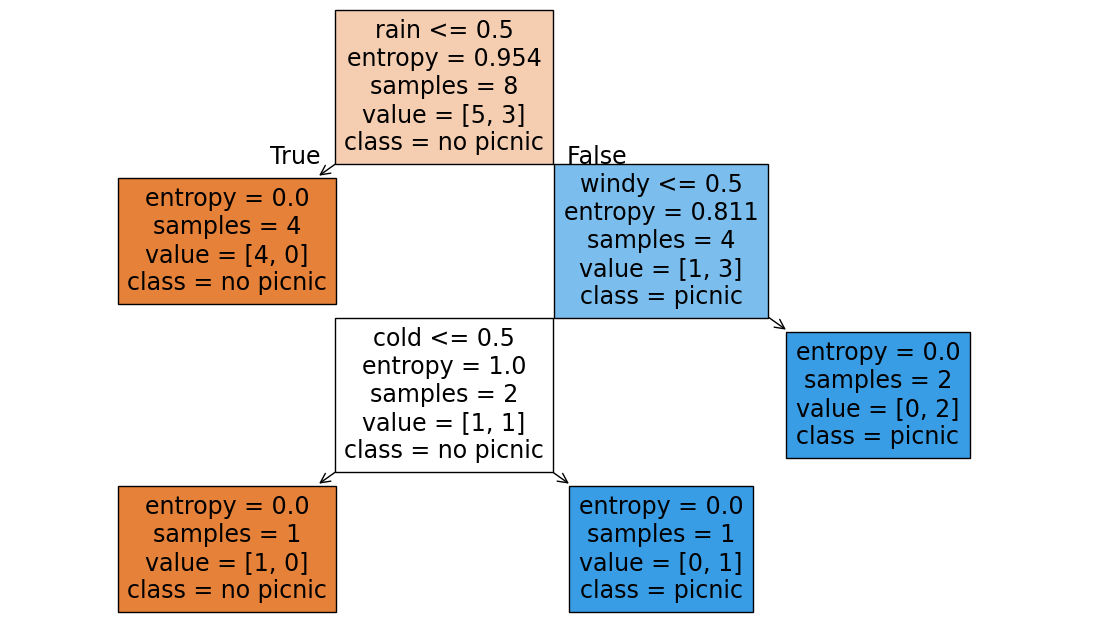

In [ ]:
plt.figure(figsize=(14, 8))

plot_tree(
    dt,
    feature_names=input_columns,
    class_names=dt.classes_,
    filled=True
)
plt.show()

In [ ]:
new_weather = pd.DataFrame({
    'rain': [0],
    'cold': [1],
    'windy': [0]
})

prediction = dt.predict(new_weather)

print(prediction)

['no picnic']
